Task 46: Pandas Data Analyzation

In [2]:
# Task 46: Exercise on Pandas Data Analyzation
import pandas as pd

# 1. Create a representative workout dataset
data = {
    'Duration': [60, 60, 60, 45, 45, 60, 450, 45],
    'Pulse': [110, 117, 103, 109, 117, 102, 104, 104],
    'Maxpulse': [130, 145, 135, 175, 148, 127, 134, 134],
    'Calories': [409.1, 479.0, 340.0, 282.4, 406.0, 300.0, 329.3, 253.3]
}
df = pd.DataFrame(data)

# 2. Inspect Dataset Structure
print("--- DataFrame Info ---")
df.info()

print("\n--- First 5 Rows (head) ---")
print(df.head())

print("\n--- Last 3 Rows (tail) ---")
print(df.tail(3))

# 3. Statistical Analysis
print("\n--- Summary Statistics (describe) ---")
print(df.describe())

# 4. Dimension & Value Inspection
print("\nShape (rows, columns):", df.shape)
print("Unique Duration values:", df['Duration'].unique())
print("Value Counts for Duration:\n", df['Duration'].value_counts())

--- DataFrame Info ---
<class 'pandas.DataFrame'>
RangeIndex: 8 entries, 0 to 7
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Duration  8 non-null      int64  
 1   Pulse     8 non-null      int64  
 2   Maxpulse  8 non-null      int64  
 3   Calories  8 non-null      float64
dtypes: float64(1), int64(3)
memory usage: 388.0 bytes

--- First 5 Rows (head) ---
   Duration  Pulse  Maxpulse  Calories
0        60    110       130     409.1
1        60    117       145     479.0
2        60    103       135     340.0
3        45    109       175     282.4
4        45    117       148     406.0

--- Last 3 Rows (tail) ---
   Duration  Pulse  Maxpulse  Calories
5        60    102       127     300.0
6       450    104       134     329.3
7        45    104       134     253.3

--- Summary Statistics (describe) ---
         Duration       Pulse    Maxpulse    Calories
count    8.000000    8.000000    8.000000    8.000000
mean 

Task 47: Pandas Data Cleaning Techniques

In [3]:
# Task 47: Exercise on Pandas Data Cleaning Techniques
import pandas as pd
import numpy as np

# 1. Dataset with common data quality issues
dirty_data = {
    'Date': ['2026/12/01', '2026/12/02', '20261203', '2026/12/04', '2026/12/04', '2026/12/05'],
    'Duration': [60, 60, 450, 45, 45, 60],        # Row 2 contains an outlier (450)
    'Pulse': [110, 117, 103, 109, 109, np.nan],    # Row 5 contains a missing value
    'Calories': [409.1, 479.0, 340.0, np.nan, np.nan, 300.0]  # Missing values & row 4 is duplicate
}

df = pd.DataFrame(dirty_data)
print("--- Raw / Dirty DataFrame ---")
print(df)

# A. Standardize Date format
df['Date'] = pd.to_datetime(df['Date'], format='mixed')

# B. Handle Missing Values
# Impute Pulse using the median
df['Pulse'] = df['Pulse'].fillna(df['Pulse'].median())

# Drop rows where Calories are completely missing
df.dropna(subset=['Calories'], inplace=True)

# C. Handle Outliers / Wrong Values
# Cap or correct unrealistic duration (> 120 minutes)
for x in df.index:
    if df.loc[x, "Duration"] > 120:
        df.loc[x, "Duration"] = 60

# D. Remove Duplicate Rows
df.drop_duplicates(inplace=True)

# Reset Index after cleaning
df.reset_index(drop=True, inplace=True)

print("\n--- Cleaned DataFrame ---")
print(df)

--- Raw / Dirty DataFrame ---
         Date  Duration  Pulse  Calories
0  2026/12/01        60  110.0     409.1
1  2026/12/02        60  117.0     479.0
2    20261203       450  103.0     340.0
3  2026/12/04        45  109.0       NaN
4  2026/12/04        45  109.0       NaN
5  2026/12/05        60    NaN     300.0

--- Cleaned DataFrame ---
        Date  Duration  Pulse  Calories
0 2026-12-01        60  110.0     409.1
1 2026-12-02        60  117.0     479.0
2 2026-12-03        60  103.0     340.0
3 2026-12-05        60  109.0     300.0


Task 48: Pandas Data Correlation & Exploratory Analysis

In [4]:
# Task 48: Exercise on Pandas Data Correlation
import pandas as pd
import numpy as np

# 1. Load sample dataset
data = {
    'Duration': [60, 60, 60, 45, 45, 60, 60, 45],
    'Pulse': [110, 117, 103, 109, 117, 102, 104, 104],
    'Maxpulse': [130, 145, 135, 175, 148, 127, 134, 134],
    'Calories': [409.1, 479.0, 340.0, 282.4, 406.0, 300.0, 374.0, 253.3]
}
df = pd.DataFrame(data)

# 2. Compute Pearson Correlation Matrix
correlation_matrix = df.corr(method='pearson', numeric_only=True)
print("--- Pearson Correlation Matrix ---")
print(correlation_matrix)

# 3. Interpret Relationships
# Values close to 1: Strong positive relationship
# Values close to -1: Strong negative relationship
# Values close to 0: No linear relationship
print("\nCorrelation with Calories:")
print(correlation_matrix['Calories'].sort_values(ascending=False))

--- Pearson Correlation Matrix ---
          Duration     Pulse  Maxpulse  Calories
Duration  1.000000 -0.238007 -0.607240  0.454712
Pulse    -0.238007  1.000000  0.426599  0.726844
Maxpulse -0.607240  0.426599  1.000000 -0.094201
Calories  0.454712  0.726844 -0.094201  1.000000

Correlation with Calories:
Calories    1.000000
Pulse       0.726844
Duration    0.454712
Maxpulse   -0.094201
Name: Calories, dtype: float64


Week 4 Complementary Practical: Seaborn EDA & GroupBy

--- Department GroupBy Aggregation ---
             Sales  Expenses
Department                  
Clothing       770     110.0
Electronics   2050     350.0
Grocery        150      50.0


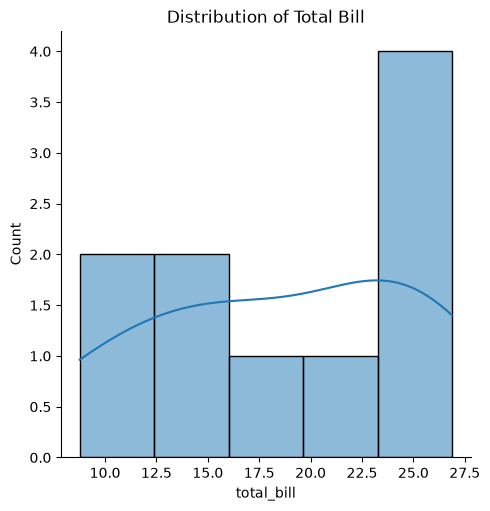

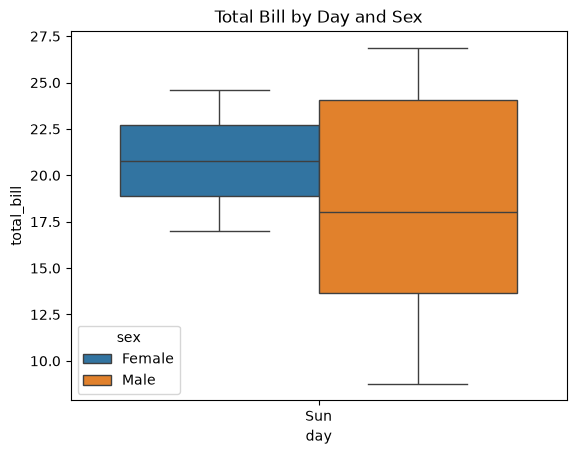

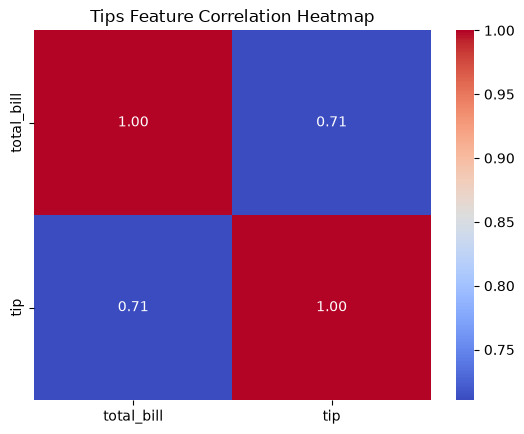

In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Merging & GroupBy
df_sales = pd.DataFrame({
    'Department': ['Electronics', 'Clothing', 'Electronics', 'Clothing', 'Grocery'],
    'Sales': [1200, 350, 850, 420, 150],
    'Expenses': [400, 100, 300, 120, 50]
})

print("--- Department GroupBy Aggregation ---")
dept_summary = df_sales.groupby('Department').agg({'Sales': 'sum', 'Expenses': 'mean'})
print(dept_summary)

# 2. Local Sample Data (bypasses online download)
tips = pd.DataFrame({
    'total_bill': [16.99, 10.34, 21.01, 23.68, 24.59, 25.29, 8.77, 26.88, 15.04, 14.78],
    'tip': [1.01, 1.66, 3.50, 3.31, 3.61, 4.71, 2.00, 3.12, 1.96, 3.23],
    'sex': ['Female', 'Male', 'Male', 'Male', 'Female', 'Male', 'Male', 'Male', 'Male', 'Male'],
    'day': ['Sun', 'Sun', 'Sun', 'Sun', 'Sun', 'Sun', 'Sun', 'Sun', 'Sun', 'Sun']
})

# A. Distribution Plot
sns.displot(tips['total_bill'], kde=True)
plt.title("Distribution of Total Bill")
plt.show()

# B. Categorical Plot
sns.boxplot(x='day', y='total_bill', data=tips, hue='sex')
plt.title("Total Bill by Day and Sex")
plt.show()

# C. Heatmap
corr = tips[['total_bill', 'tip']].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Tips Feature Correlation Heatmap")
plt.show()